In [1]:
import numpy as np
from collections import Counter
from qiskit import QuantumCircuit
from qiskit.quantum_info import Operator 
from qiskit import QuantumCircuit, transpile
#from qiskit_ibm_runtime import EstimatorV2 as Estimator
from qiskit_ibm_runtime import SamplerV2 as Sampler
from qiskit.quantum_info import PauliList
from qiskit_aer import AerSimulator
from qiskit.quantum_info import SparsePauliOp
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
import itertools
import time
import quimb.tensor as qtn
import jax

jax.config.update("jax_enable_x64", True)

# ============================================================
# Initialize Quimb MPS
# ============================================================
# system size
L = 104
print(f"L= {L}")

MAX_BOND = 128
CUTOFF = 1e-10

circ_mps = qtn.CircuitMPS(N=L, max_bond=MAX_BOND, cutoff=CUTOFF)

# -------------------------------------------------------------
# 1. Custom Gates 
# -------------------------------------------------------------
def Hzx_xz_quimb(circ_mps, theta, i, j):
    """
    Implements exp[-i theta/2 (Z_i X_j + X_i Z_j)]

    assuming the same convention as the Qiskit Hzx_xz gate.
    """

    # -------------------------
    # exp[-i theta/2 Z_i X_j]
    # -------------------------
    circ_mps.h(j)
    circ_mps.rzz(theta, i, j)
    circ_mps.h(j)

    # -------------------------
    # exp[-i theta/2 X_i Z_j]
    # -------------------------
    circ_mps.h(i)
    circ_mps.rzz(theta, i, j)
    circ_mps.h(i)

    return circ_mps

# -------------------------------------------------------------
# 2. Physics Parameters
# -------------------------------------------------------------
a = 1.0
g = np.sqrt(1.2/a)

J = -3*(g**2)/16
hz = -2*J
hx = -2/((a*g)**2)



# 2-qubit Pauli basis (16 operators)
Psingle = ["I", "X", "Y", "Z"]
Pauli_combination = [(p1, p2, p3) for p1 in Psingle for p2 in Psingle for p3 in Psingle]
# Build ρ = (1/2^2) Σ exp[P] * P
matrices = [SparsePauliOp.from_list([(p1+p2+p3, 1)]).to_matrix() for (p1,p2,p3) in Pauli_combination]
print(Pauli_combination)


L= 104
[('I', 'I', 'I'), ('I', 'I', 'X'), ('I', 'I', 'Y'), ('I', 'I', 'Z'), ('I', 'X', 'I'), ('I', 'X', 'X'), ('I', 'X', 'Y'), ('I', 'X', 'Z'), ('I', 'Y', 'I'), ('I', 'Y', 'X'), ('I', 'Y', 'Y'), ('I', 'Y', 'Z'), ('I', 'Z', 'I'), ('I', 'Z', 'X'), ('I', 'Z', 'Y'), ('I', 'Z', 'Z'), ('X', 'I', 'I'), ('X', 'I', 'X'), ('X', 'I', 'Y'), ('X', 'I', 'Z'), ('X', 'X', 'I'), ('X', 'X', 'X'), ('X', 'X', 'Y'), ('X', 'X', 'Z'), ('X', 'Y', 'I'), ('X', 'Y', 'X'), ('X', 'Y', 'Y'), ('X', 'Y', 'Z'), ('X', 'Z', 'I'), ('X', 'Z', 'X'), ('X', 'Z', 'Y'), ('X', 'Z', 'Z'), ('Y', 'I', 'I'), ('Y', 'I', 'X'), ('Y', 'I', 'Y'), ('Y', 'I', 'Z'), ('Y', 'X', 'I'), ('Y', 'X', 'X'), ('Y', 'X', 'Y'), ('Y', 'X', 'Z'), ('Y', 'Y', 'I'), ('Y', 'Y', 'X'), ('Y', 'Y', 'Y'), ('Y', 'Y', 'Z'), ('Y', 'Z', 'I'), ('Y', 'Z', 'X'), ('Y', 'Z', 'Y'), ('Y', 'Z', 'Z'), ('Z', 'I', 'I'), ('Z', 'I', 'X'), ('Z', 'I', 'Y'), ('Z', 'I', 'Z'), ('Z', 'X', 'I'), ('Z', 'X', 'X'), ('Z', 'X', 'Y'), ('Z', 'X', 'Z'), ('Z', 'Y', 'I'), ('Z', 'Y', 'X'), ('Z', 

In [3]:
# -------------------------------------------------------------
# 3. Create main evolution circuit
# -------------------------------------------------------------
def quant_circuit(circ_mps, delta_t):
    theta_1 = J*2*delta_t
    theta_2 = hz*2*delta_t
    theta_3 = (hx/16)*2*delta_t
    theta_4 = -(3*hx/16)*2*delta_t
    theta_5 = -(3*hx/16)*2*delta_t
    theta_6 = (9*hx/16)*2*delta_t

    for i in range(0,L-1,2):
        circ_mps.rzz(theta_1, i, i+1)
    for i in range(1,L-1,2):
        circ_mps.rzz(theta_1, i, i+1)
    #circ_mps.barrier()
    for i in range(L):
        circ_mps.rz(theta_2, i)
    for i in range(L):
        circ_mps.rx(theta_3, i)

    for i in range(0,L-1, 2):
        Hzx_xz_quimb(circ_mps, theta_4, i, i+1)
    for i in range(1,L-1, 2):
        Hzx_xz_quimb(circ_mps, theta_4, i, i+1)

    for i in range(0, L - 1, 2):
        circ_mps.cz(i, i+1)
    for i in range(1, L - 1, 2):  
        circ_mps.cz(i, i+1)
    
    for i in range(1, L - 1):
        circ_mps.rx(theta_6, i)
        
    for i in range(0, L - 1, 2):
        circ_mps.cz(i, i+1)
    for i in range(1, L - 1, 2):  
        circ_mps.cz(i, i+1)
    #circ_mps.barrier()
    return circ_mps

# -------------------------------------------------------------
# 4. Construct reduced density matrix
# -------------------------------------------------------------
def reduced_density_matrix(circ_mps,qA,qB,qC):

    # Current MPS state
    psi = circ_mps.psi

    # Keep only qA, qB, qC and trace out everything else
    rho = psi.partial_trace_to_dense_canonical((qA, qB, qC),normalized=True)

    rho = np.asarray(rho, dtype=complex)

    # Ensure matrix form
    rho = rho.reshape(2**3,2**3)

    # Small numerical symmetrization
    rho = 0.5 * ( rho+rho.conj().T)

    # Normalize explicitly
    #rho = rho / np.trace(rho)

    return rho
# -------------------------------------------------------------
# 5. Calculate Renyi-2 entropy from rho
# -------------------------------------------------------------

def calculate_Renyi2(rho):

    print(f"trace rho = {np.trace(rho)}")

    # Eigenvalues
    vals = np.linalg.eigvalsh(rho)
    vals = np.real(vals)
    # -------------------------------------------
    # Moments
    # -------------------------------------------
    R1 = np.sum(vals)
    R2 = np.sum(vals**2)
    # R2 = np.real(np.trace(rho @ rho))
    
    S_A = -np.log(R2)

    print(f"R1 = {R1}")
    print(f"R2 = {R2}")

    return S_A, R1, R2


In [4]:
# Calculate the Renyi2 entropy
#-----------------------------------------------------------------
#--------------------------------------------------------------------------
# Times and number of trotter steps
#-------------------------------------------------------------------------
Num_step = 10
total_t = 0
initial_t = 0.0
final_t = 3.0

times = []
entropies = []

real_time_step = []
# -------------------------------------------------------------
# 5. Main Time Evolution Loop
# -------------------------------------------------------------
# Begining of Quantum Circuit
qc_tot_step0 = qtn.CircuitMPS( N=L, max_bond=MAX_BOND, cutoff=1e-10)
for i in range(L):
    qc_tot_step0.x(i)
    
# target = qubit index whose entropy you measure
qA = (L//2)-1
qB = L//2
qC = (L//2)+1

time_t0 = time.perf_counter()

rho = reduced_density_matrix(qc_tot_step0,qA,qB,qC)
S_A, R1, R2 = calculate_Renyi2(rho)

times.append(total_t)
entropies.append(S_A)

print(f"Time = {total_t:.3f}")
print(f"Entanglement entropy : {S_A:.4f}")
print(f"------------------------------------")

# Calculate the real time to simulate this step
dt_time_step0 = time.perf_counter() - time_t0
real_time_step.append(dt_time_step0)


time_step = (final_t-initial_t)/Num_step

qc_tot = qtn.CircuitMPS( N=L, max_bond=MAX_BOND, cutoff=1e-10)
for i in range(L):
    qc_tot.x(i)
    
for i in range(Num_step):
    time_start = time.perf_counter()
    
    delta_t = time_step
    total_t = total_t + delta_t

    # Add Quantum Circuit with qc_tot_V2
    qc_tot = quant_circuit(qc_tot, delta_t)

    rho = reduced_density_matrix(qc_tot,qA,qB,qC)
    S_A, R1, R2 = calculate_Renyi2(rho)

    times.append(total_t)
    entropies.append(S_A)

    print(f"Time = {total_t:.3f}")
    print(f"Entanglement entropy : {S_A:.4f}")
    
    # Calculate the real time to simulate this step
    dt_time_stepi = time.perf_counter() - time_start
    print(f"time for computation = {dt_time_stepi:.3f}")
    print(f"------------------------------------\n")
    real_time_step.append(dt_time_stepi)

    

print(f"times = {times}")
print(f"entropy = {entropies}")

real_time_step = np.array(real_time_step)
print(f"real_time_step = {real_time_step}")

# -------------------------------------------------------------
# 7. Save results
# -------------------------------------------------------------
A=3
entropy_filename = f"Renyi2_vs_time10_N{L}_A{A}_SIMULATOR_QUIBM_MPS.txt"

np.savetxt(entropy_filename, np.column_stack([times, entropies]),
           header="time  S_A", fmt="%.6f  %.6f")

np.savetxt(f"real_time_required_L{L}_NA{A}_QUIBM_MPS.txt", real_time_step)
#circ_R.draw("mpl")

trace rho = (1+0j)
R1 = 1.0
R2 = 1.0
Time = 0.000
Entanglement entropy : -0.0000
------------------------------------
trace rho = (1+0j)
R1 = 0.9999999999999996
R2 = 0.6158821159332406
Time = 0.300
Entanglement entropy : 0.4847
time for computation = 0.654
------------------------------------

trace rho = (1+0j)
R1 = 1.0000000000000004
R2 = 0.27517683433784124
Time = 0.600
Entanglement entropy : 1.2903
time for computation = 0.568
------------------------------------

trace rho = (0.9999999999999999+0j)
R1 = 1.0
R2 = 0.3300584535887824
Time = 0.900
Entanglement entropy : 1.1085
time for computation = 0.586
------------------------------------

trace rho = (0.9999999999999998+0j)
R1 = 0.9999999999999996
R2 = 0.25584840690693983
Time = 1.200
Entanglement entropy : 1.3632
time for computation = 0.608
------------------------------------

trace rho = (0.9999999999999998+0j)
R1 = 0.9999999999999999
R2 = 0.281941817598442
Time = 1.500
Entanglement entropy : 1.2661
time for computation = 0.65

In [5]:
# Define the basis gate of quimb circuits
def quimb_basis_gate():
    basis_gates=["x","h","rx","ry", "rz", "rzz", "cx", "cz",]
    return basis_gates

In [8]:
import time
import numpy as np
from scipy.optimize import minimize
from qiskit_aer import AerSimulator
from qiskit_addon_aqc_tensor.simulation import tensornetwork_from_circuit
from qiskit_addon_aqc_tensor.simulation.aer import QiskitAerSimulationSettings
from qiskit_addon_aqc_tensor.ansatz_generation import generate_ansatz_from_circuit
from qiskit_addon_aqc_tensor.objective import MaximizeStateFidelity
from qiskit_quimb import SUPPORTED_GATES
from functools import partial
from scipy.optimize import minimize
from qiskit import QuantumCircuit
from qiskit_addon_aqc_tensor.simulation import (tensornetwork_from_circuit,)
from qiskit_addon_aqc_tensor.simulation.quimb import (QuimbSimulator,)
from qiskit_addon_aqc_tensor.ansatz_generation import ( generate_ansatz_from_circuit,)
from qiskit_addon_aqc_tensor.objective import (MaximizeStateFidelity,)
import jax
jax.config.update("jax_enable_x64", True)

AQC_BOND         = 128    # MPS max bond dimension (raise if fidelity looks truncation-capped)
AQC_CUTOFF = 1e-10

sim_settings = QuimbSimulator(
    partial(qtn.CircuitMPS,max_bond=AQC_BOND,cutoff=AQC_CUTOFF,), autodiff_backend="jax",)

def quimb_basis_gate():
    basis_gates=["x","h","rx","ry", "rz", "rzz", "cx", "cz",]
    return basis_gates

def multy_trotter_steps(L, delta_t, num_steps):
    qc = QuantumCircuit(L)
    for i in range(L):
        qc.x(i)
    for j in range(num_steps):
        theta_1 = J*2*delta_t
        theta_2 = hz*2*delta_t
        theta_3 = (hx/16)*2*delta_t
        theta_4 = -(3*hx/16)*2*delta_t
        theta_5 = -(3*hx/16)*2*delta_t
        theta_6 = (9*hx/16)*2*delta_t


        for i in range(0,L-1,2): qc.rzz(theta_1, i, i+1)
        for i in range(1,L-1,2): qc.rzz(theta_1, i, i+1)
        #qc_tot.barrier()
        for i in range(L): qc.rz(theta_2, i)
        for i in range(L): qc.rx(theta_3, i)

        for i in range(0,L-1, 2): Hzx_xz_quimb(qc, theta_4, i, i+1)
        for i in range(1,L-1, 2): Hzx_xz_quimb(qc, theta_4, i, i+1)

        for i in range(0, L-1, 2): qc.cz(i, i+1)
        for i in range(1, L-1, 2): qc.cz(i, i+1)
    
        for i in range(1, L-1): qc.rx(theta_6, i)
        
        for i in range(0, L-1, 2): qc.cz(i, i+1)
        for i in range(1, L-1, 2): qc.cz(i, i+1)

    return qc

#--------------------------------------------------------------------------
# Times and number of trotter steps
#-------------------------------------------------------------------------
time_step = (final_t-initial_t)/Num_step

# proto type of one trotter step with time n*dt
prototype_AQC2 = multy_trotter_steps(L, delta_t= time_step, num_steps=1).decompose()
prototype_quibm = transpile(prototype_AQC2 , basis_gates=quimb_basis_gate(), optimization_level=3)

# Generating an ansatz from the prototype with time t= n*dt
ansatz, initial_params = generate_ansatz_from_circuit(prototype_AQC2)

print(f"Number of parameters = {len(initial_params)}")


Number of parameters = 4020


In [9]:
# Optimized parameters for compressing 6 trotter steps and make one AQC block
opt_para_AQC_6 = np.loadtxt("opt_params_AQC_6_steps_dt_0p3.txt")

print("Number of optimized parameters =", len(opt_para_AQC_6))

# Construct optimized AQC circuit
optimized_circuit = ansatz.assign_parameters(dict(zip(ansatz.parameters, opt_para_AQC_6)))

print("Remaining free parameters =", optimized_circuit.num_parameters)

Number of optimized parameters = 4020
Remaining free parameters = 0


In [10]:
# ============================================================
# Construct optimized AQC state as a Quimb MPS
# ============================================================
# Convert  optimized AQC qiskit circuit into gates supported by qiskit-quimb
optimized_circuit_quimb = transpile(optimized_circuit, basis_gates=quimb_basis_gate(), optimization_level=0)

print("Optimized circuit gates:")
print(optimized_circuit_quimb.count_ops())

# Convert Qiskit circuit -> Quimb CircuitMPS
optimized_mps = tensornetwork_from_circuit(optimized_circuit_quimb, sim_settings)

print("type =", type(optimized_mps))
print("max bond =", optimized_mps.psi.max_bond())
#=================================================================

# AQC replacement occurs after 5 Trotter steps
AQC_REPLACE_STEP = 6
AQC_REPLACE_TIME = AQC_REPLACE_STEP * time_step   # = 1.8
print(f"AQC_REPLACE_TIME = {AQC_REPLACE_TIME}")

# Subsystem
qA = (L // 2) - 1
qB = L // 2
qC = (L // 2) + 1


times_AQC = []
entropies_AQC = []
real_time_step_AQC = []

time_t0_AQC = time.perf_counter()

qc_tot = qtn.CircuitMPS( N=L, max_bond=MAX_BOND, cutoff=1e-10)
for i in range(L):
    qc_tot.x(i)


total_t = 0.0

rho = reduced_density_matrix(qc_tot,qA,qB,qC)
S_A, R1, R2 = calculate_Renyi2(rho)

print(f"Time = {total_t:.3f}")
print(f"Renyi-2 entropy = {S_A:.6f}")
print(f"-----------------------------------")
times_AQC.append(total_t)
entropies_AQC.append(S_A)

# Calculate the real time to simulate this step
dt_time_step0_AQC = time.perf_counter() - time_t0_AQC
real_time_step_AQC.append(dt_time_step0_AQC)


# =============================================================
# Time evolution
# =============================================================
delta_t = time_step
for step in range(1, Num_step + 1):
    time_start = time.perf_counter()

    total_t = step * delta_t

    # ---------------------------------------------------------
    # Before t = 1.5:
    # ordinary Trotter evolution
    # ---------------------------------------------------------

    if step < AQC_REPLACE_STEP:

        qc_tot = quant_circuit(qc_tot,delta_t)

        print(f"\nStep {step}: ordinary Trotter circuit, t = {total_t:.3f}")


    # ---------------------------------------------------------
    # Exactly at t = 1.8:
    #
    # REPLACE the entire accumulated 6-step evolution by the
    # optimized AQC circuit.
    # ---------------------------------------------------------

    elif step == AQC_REPLACE_STEP:
        
        qc_tot = optimized_mps.copy()

        print(f"\n=======================================")
        print(f"Step {step}: replacing {step} Trotter steps")
        print(f"with optimized AQC circuit at t = {total_t:.3f}" )
        print(f"=======================================" )

    else:
        qc_tot = quant_circuit( qc_tot, delta_t )

        print(f"\nStep {step}: Trotter evolution after AQC, t = {total_t:.3f}")

    # ---------------------------------------------------------
    # Calculate entropy
    # ---------------------------------------------------------
    rho = reduced_density_matrix(qc_tot,qA,qB,qC)
    S_A, R1, R2 = calculate_Renyi2(rho)

    print(f"Time = {total_t:.3f}")
    print(f"Renyi-2 entropy = {S_A:.6f}")
    print(f"-----------------------------------")

    times_AQC.append(total_t)
    entropies_AQC.append(S_A)
    
    # Calculate the real time to simulate this step
    dt_time_stepi_AQC = time.perf_counter() - time_start
    real_time_step_AQC.append(dt_time_stepi_AQC)

real_time_step_AQC = np.array(real_time_step_AQC)
print(f"real_time_step_AQC = {real_time_step_AQC}")
# =============================================================
# Print results
# =============================================================

print("\n=======================================")
print("FINAL RESULTS")
print("=======================================")

# -------------------------------------------------------------
# 7. Save results
# -------------------------------------------------------------
entropy_filename = f"Renyi2_vs_time10_N{L}_A{A}_SIMULATOR_AQC_QUIMB_MPS_V2.txt"

np.savetxt(entropy_filename, np.column_stack([times_AQC, entropies_AQC]),
           header="time  S_A", fmt="%.6f  %.6f")
np.savetxt(f"real_time_required_L{L}_NA{A}_AQC_QUIMB_MPS_V2.txt", real_time_step_AQC)
#circ_R.draw("mpl")


Optimized circuit gates:
OrderedDict({'rz': 3092, 'cx': 1236, 'rx': 928, 'ry': 824})
type = <class 'quimb.tensor.circuit.CircuitMPS'>
max bond = 29
AQC_REPLACE_TIME = 1.7999999999999998
trace rho = (1+0j)
R1 = 1.0
R2 = 1.0
Time = 0.000
Renyi-2 entropy = -0.000000
-----------------------------------

Step 1: ordinary Trotter circuit, t = 0.300
trace rho = (1+0j)
R1 = 0.9999999999999996
R2 = 0.6158821159332406
Time = 0.300
Renyi-2 entropy = 0.484700
-----------------------------------

Step 2: ordinary Trotter circuit, t = 0.600
trace rho = (1+0j)
R1 = 1.0000000000000004
R2 = 0.27517683433784124
Time = 0.600
Renyi-2 entropy = 1.290341
-----------------------------------

Step 3: ordinary Trotter circuit, t = 0.900
trace rho = (0.9999999999999999+0j)
R1 = 1.0
R2 = 0.3300584535887824
Time = 0.900
Renyi-2 entropy = 1.108486
-----------------------------------

Step 4: ordinary Trotter circuit, t = 1.200
trace rho = (0.9999999999999998+0j)
R1 = 0.9999999999999996
R2 = 0.25584840690693983
Tim

In [11]:
print("times =")
print(times_AQC)

entropies_AQC = np.array(entropies_AQC)
print("\nentropies =")
print(entropies_AQC)

times =
[0.0, 0.3, 0.6, 0.8999999999999999, 1.2, 1.5, 1.7999999999999998, 2.1, 2.4, 2.6999999999999997, 3.0]

entropies =
[-0.          0.4846997   1.29034135  1.10848551  1.36317017  1.26605455
  1.47417773  1.59615833  1.34769126  1.07945315  0.93533992]


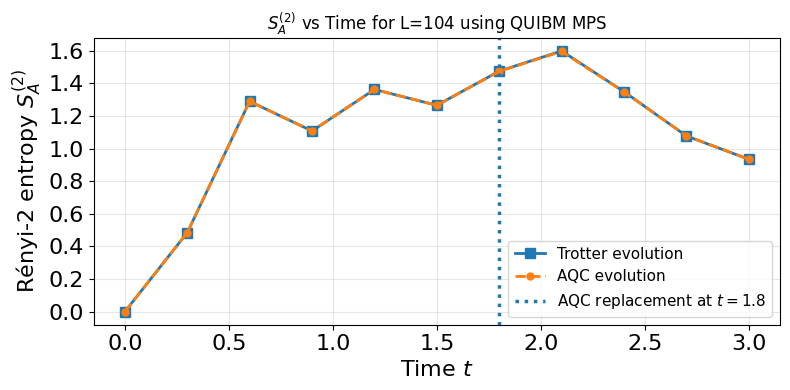

In [12]:
filename = f"Renyi2_vs_time10_N{L}_A{A}_SIMULATOR_QUIBM_MPS.txt"
data = np.loadtxt(filename, skiprows=1)
times = data[:,0]
S_2 = data[:,1]

import numpy as np
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------
plt.figure(figsize=(8, 4))

plt.plot(times, S_2, "-s", lw=2,markersize=7, label="Trotter evolution")
plt.plot(times_AQC, entropies_AQC,  "--o", markersize=5, lw=2, label="AQC evolution")
plt.axvline(x=AQC_REPLACE_TIME,linestyle=":",lw=2.5,label=fr"AQC replacement at $t={AQC_REPLACE_TIME:.1f}$")

plt.xlabel(r"Time $t$", fontsize=16)
plt.ylabel(r"Rényi-2 entropy $S_A^{(2)}$", fontsize=16)
plt.title(fr"$S_A^{{(2)}}$ vs Time for L={L} using QUIBM MPS")
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)

plt.legend(fontsize=11)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


In [13]:
# Optimized parameters for compressing 2 trotter steps into 1 AQC block
opt_para_AQC_2 = np.loadtxt("opt_params_AQC_2_steps_dt_0p3.txt")

print("Number of optimized parameters =", len(opt_para_AQC_2))

# Construct optimized AQC circuit
optimized_circuit_AQC2 = ansatz.assign_parameters(dict(zip(ansatz.parameters, opt_para_AQC_2)))

print("Remaining free parameters =", optimized_circuit_AQC2.num_parameters)

##################################################################################
# Optimized parameters for compressing 4 trotter steps into 1 AQC block
opt_para_AQC_4 = np.loadtxt("opt_params_AQC_4_steps_dt_0p3.txt")

print("Number of optimized parameters =", len(opt_para_AQC_4))

# Construct optimized AQC circuit
optimized_circuit_AQC4 = ansatz.assign_parameters(dict(zip(ansatz.parameters, opt_para_AQC_4)))

print("Remaining free parameters =", optimized_circuit_AQC4.num_parameters)

#####################################################################################
# Optimized parameters for compressing 6 trotter steps into 1 AQC block
opt_para_AQC_6 = np.loadtxt("opt_params_AQC_6_steps_dt_0p3.txt")

print("Number of optimized parameters =", len(opt_para_AQC_6))

# Construct optimized AQC circuit
optimized_circuit_AQC6 = ansatz.assign_parameters(dict(zip(ansatz.parameters, opt_para_AQC_6)))

print("Remaining free parameters =", optimized_circuit_AQC6.num_parameters)

#####################################################################################################################

Number of optimized parameters = 4020
Remaining free parameters = 0
Number of optimized parameters = 4020
Remaining free parameters = 0
Number of optimized parameters = 4020
Remaining free parameters = 0


In [14]:
# Optimized circuits at selected time steps
AQC_circuits = {
    2: optimized_circuit_AQC2,
    4: optimized_circuit_AQC4,
    6: optimized_circuit_AQC6,
}

#=================================================================
# Subsystem
qA = (L // 2) - 1
qB = L // 2
qC = (L // 2) + 1

times_AQC_V3 = []
entropies_AQC_V3 = []
real_time_step_AQC_V3 = []

time_t0_AQC_V3 = time.perf_counter()

qc_tot = qtn.CircuitMPS( N=L, max_bond=MAX_BOND, cutoff=1e-10)
for i in range(L):
    qc_tot.x(i)


total_t = 0.0

rho = reduced_density_matrix(qc_tot,qA,qB,qC)
S_A, R1, R2 = calculate_Renyi2(rho)

print(f"Time = {total_t:.3f}")
print(f"Renyi-2 entropy = {S_A:.6f}")
print(f"-----------------------------------")
times_AQC_V3.append(total_t)
entropies_AQC_V3.append(S_A)

# Calculate the real time to simulate this step
dt_time_step0_AQC_V3 = time.perf_counter() - time_t0_AQC_V3
real_time_step_AQC_V3.append(dt_time_step0_AQC_V3)


# =============================================================
# Time evolution
# =============================================================
delta_t = time_step
for step in range(1, Num_step + 1):
    time_start = time.perf_counter()

    total_t = step * delta_t

    # ---------------------------------------------------------
    # Replace the Trotter evolution with optimized AQC circuits
    # before measuring the state at the current time.
    # ---------------------------------------------------------
    if step in AQC_circuits:
        # Get optimized AQC circuit
        qc_AQC = AQC_circuits[step].copy()

        # Decompose custom gates into supported gates
        qc_AQC_transpile = transpile( qc_AQC,   basis_gates=quimb_basis_gate(), optimization_level=0)

        # Convert Qiskit circuit -> Quimb CircuitMPS
        qc_tot = tensornetwork_from_circuit(qc_AQC_transpile, sim_settings)
        print("type =", type(qc_tot))
        print("max bond =", qc_tot.psi.max_bond())


        print(f"Using optimized AQC circuit at "
              f"step = {step}, t = {total_t:.3f}")


    else:
        qc_tot = quant_circuit(qc_tot, delta_t)

        print(f"Using Trotter evolution at step {step}")

    # ---------------------------------------------------------
    # Calculate entropy
    # ---------------------------------------------------------
    rho = reduced_density_matrix(qc_tot,qA,qB,qC)
    S_A, R1, R2 = calculate_Renyi2(rho)

    print(f"Time = {total_t:.3f}")
    print(f"Renyi-2 entropy = {S_A:.6f}")
    print(f"-----------------------------------")

    times_AQC_V3.append(total_t)
    entropies_AQC_V3.append(S_A)
    
    # Calculate the real time to simulate this step
    dt_time_stepi_AQC_V3 = time.perf_counter() - time_start
    real_time_step_AQC_V3.append(dt_time_stepi_AQC_V3)

real_time_step_AQC_V3 = np.array(real_time_step_AQC_V3)
print(f"real_time_step_AQC_V3 = {real_time_step_AQC_V3}")
# =============================================================
# Print results
# =============================================================

print("\n=======================================")
print("FINAL RESULTS")
print("=======================================")

# -------------------------------------------------------------
# 7. Save results
# -------------------------------------------------------------
entropy_filename = f"Renyi2_vs_time10_N{L}_A{A}_SIMULATOR_AQC_QUIMB_MPS_V3.txt"

np.savetxt(entropy_filename, np.column_stack([times_AQC_V3, entropies_AQC_V3]),
           header="time  S_A", fmt="%.6f  %.6f")
np.savetxt(f"real_time_required_L{L}_NA{A}_AQC_QUIMB_MPS_V3.txt", real_time_step_AQC_V3)
#circ_R.draw("mpl")


trace rho = (1+0j)
R1 = 1.0
R2 = 1.0
Time = 0.000
Renyi-2 entropy = -0.000000
-----------------------------------
Using Trotter evolution at step 1
trace rho = (1+0j)
R1 = 0.9999999999999996
R2 = 0.6158821159332406
Time = 0.300
Renyi-2 entropy = 0.484700
-----------------------------------
type = <class 'quimb.tensor.circuit.CircuitMPS'>
max bond = 9
Using optimized AQC circuit at step = 2, t = 0.600
trace rho = (1+0j)
R1 = 1.0
R2 = 0.27517635050896044
Time = 0.600
Renyi-2 entropy = 1.290343
-----------------------------------
Using Trotter evolution at step 3
trace rho = (1+0j)
R1 = 1.0000000000000002
R2 = 0.3300328934081754
Time = 0.900
Renyi-2 entropy = 1.108563
-----------------------------------
type = <class 'quimb.tensor.circuit.CircuitMPS'>
max bond = 17
Using optimized AQC circuit at step = 4, t = 1.200
trace rho = (0.9999999999999999+0j)
R1 = 1.0
R2 = 0.2558312846265515
Time = 1.200
Renyi-2 entropy = 1.363237
-----------------------------------
Using Trotter evolution at step

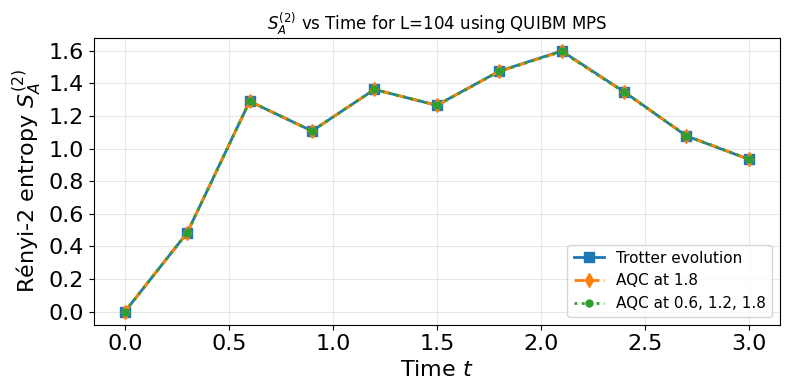

In [15]:
filename = f"Renyi2_vs_time10_N{L}_A{A}_SIMULATOR_QUIBM_MPS.txt"
data = np.loadtxt(filename, skiprows=1)
times = data[:,0]
S_2 = data[:,1]

filename_V2 = f"Renyi2_vs_time10_N{L}_A{A}_SIMULATOR_AQC_QUIMB_MPS_V2.txt"
data_V2 = np.loadtxt(filename_V2, skiprows=1)
times_V2 = data_V2[:,0]
S_2_V2 = data_V2[:,1]

import numpy as np
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------
plt.figure(figsize=(8, 4))

plt.plot(times, S_2, "-s", lw=2,markersize=7, label="Trotter evolution")
plt.plot(times_V2, S_2_V2, "--d", lw=2,markersize=7, label="AQC at 1.8")
plt.plot(times_AQC_V3, entropies_AQC_V3,  ":o", markersize=5, lw=2, label="AQC at 0.6, 1.2, 1.8")
#plt.axvline(x=1.0,linestyle=":",lw=2.5, color="red", label="AQC replacement at $t=0.6$")


plt.xlabel(r"Time $t$", fontsize=16)
plt.ylabel(r"Rényi-2 entropy $S_A^{(2)}$", fontsize=16)
plt.title(fr"$S_A^{{(2)}}$ vs Time for L={L} using QUIBM MPS")
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)

plt.legend(fontsize=11)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


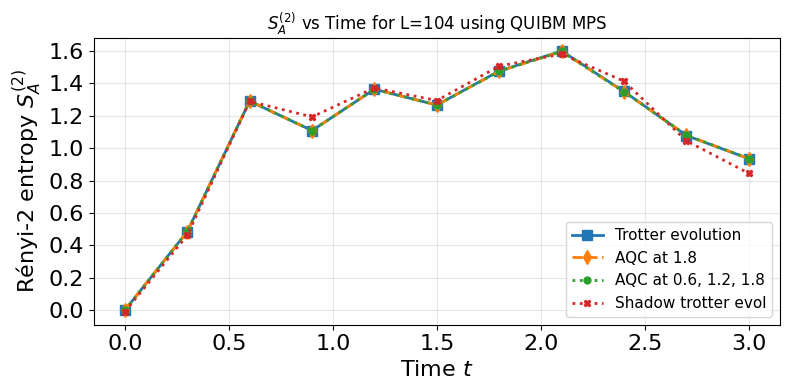

In [17]:
filename = f"Renyi2_vs_time10_N{L}_A{A}_SIMULATOR_QUIBM_MPS.txt"
data = np.loadtxt(filename, skiprows=1)
times = data[:,0]
S_2 = data[:,1]

filename_V2 = f"Renyi2_vs_time10_N{L}_A{A}_SIMULATOR_AQC_QUIMB_MPS_V2.txt"
data_V2 = np.loadtxt(filename_V2, skiprows=1)
times_V2 = data_V2[:,0]
S_2_V2 = data_V2[:,1]


data_shadow = np.loadtxt(f"entropy_shadow_quimb_witout_AQC.txt")
SA_shadow = data_shadow[:]

import numpy as np
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------
plt.figure(figsize=(8, 4))

plt.plot(times, S_2, "-s", lw=2,markersize=7, label="Trotter evolution")
plt.plot(times_V2, S_2_V2, "--d", lw=2,markersize=7, label="AQC at 1.8")
plt.plot(times_AQC_V3, entropies_AQC_V3,  ":o", markersize=5, lw=2, label="AQC at 0.6, 1.2, 1.8")
plt.plot(times_AQC_V3, SA_shadow ,  ":X", markersize=5, lw=2, label="Shadow trotter evol")
#plt.axvline(x=1.0,linestyle=":",lw=2.5, color="red", label="AQC replacement at $t=0.6$")


plt.xlabel(r"Time $t$", fontsize=16)
plt.ylabel(r"Rényi-2 entropy $S_A^{(2)}$", fontsize=16)
plt.title(fr"$S_A^{{(2)}}$ vs Time for L={L} using QUIBM MPS")
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)

plt.legend(fontsize=11)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


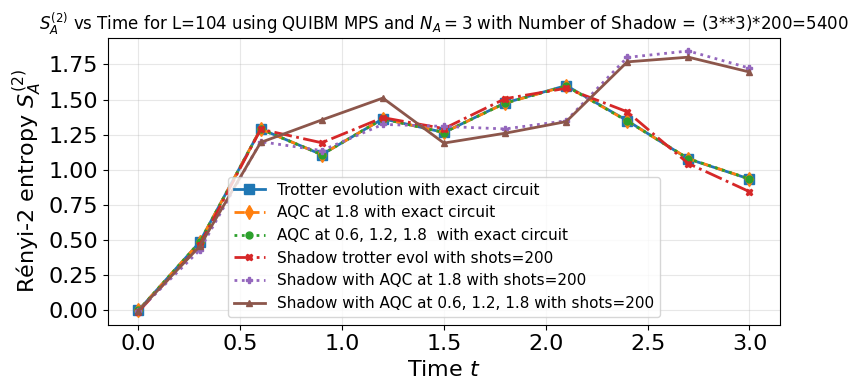

In [18]:
filename = f"Renyi2_vs_time10_N{L}_A{A}_SIMULATOR_QUIBM_MPS.txt"
data = np.loadtxt(filename, skiprows=1)
times = data[:,0]
S_2 = data[:,1]

filename_V2 = f"Renyi2_vs_time10_N{L}_A{A}_SIMULATOR_AQC_QUIMB_MPS_V2.txt"
data_V2 = np.loadtxt(filename_V2, skiprows=1)
times_V2 = data_V2[:,0]
S_2_V2 = data_V2[:,1]


data_shadow = np.loadtxt(f"entropy_shadow_quimb_witout_AQC.txt")
SA_shadow = data_shadow[:]

data_shadow_AQC = np.loadtxt(f"entropy_shadow_quimb_with_AQC_at1p8.txt")
SA_shadow_AQC = data_shadow_AQC[:]

data_shadow_AQC_V2 = np.loadtxt(f"entropy_shadow_quimb_with_AQC.txt")
SA_shadow_AQC_V2 = data_shadow_AQC_V2[:]

import numpy as np
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------
plt.figure(figsize=(8, 4))

plt.plot(times, S_2, "-s", lw=2,markersize=7, label="Trotter evolution with exact circuit")
plt.plot(times_V2, S_2_V2, "--d", lw=2,markersize=7, label="AQC at 1.8 with exact circuit")
plt.plot(times_AQC_V3, entropies_AQC_V3,  ":o", markersize=5, lw=2, label="AQC at 0.6, 1.2, 1.8  with exact circuit")
plt.plot(times_AQC_V3, SA_shadow ,  "-.X", markersize=5, lw=2, label="Shadow trotter evol with shots=200")
plt.plot(times_AQC_V3, SA_shadow_AQC ,  ":P", markersize=5, lw=2, label="Shadow with AQC at 1.8 with shots=200")
plt.plot(times_AQC_V3, SA_shadow_AQC_V2 ,  "-^", markersize=5, lw=2, label="Shadow with AQC at 0.6, 1.2, 1.8 with shots=200")
#plt.axvline(x=1.0,linestyle=":",lw=2.5, color="red", label="AQC replacement at $t=0.6$")


plt.xlabel(r"Time $t$", fontsize=16)
plt.ylabel(r"Rényi-2 entropy $S_A^{(2)}$", fontsize=16)
plt.title(fr"$S_A^{{(2)}}$ vs Time for L={L} using QUIBM MPS and $N_A=3$ with Number of Shadow = (3**3)*200=5400")
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)

plt.legend(fontsize=11)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()
